In [10]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import smarts_cerebellum.globals as gl

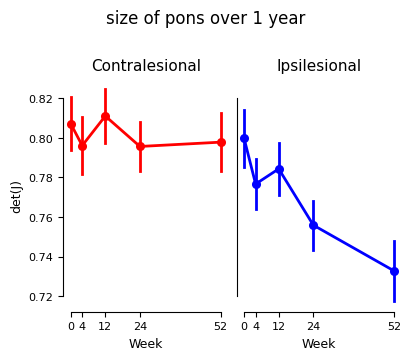

In [11]:
obs = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_trans', 'summary_MNISymC_MCP_pons_T1_to-MNI152NLin2009cSymC_mode-image_detJ.tsv'), sep = '\t')
obs = obs[obs.isPatient == 1]

colours = ['r', 'blue']

fig, axs = plt.subplots(1, 2, figsize = (4, 3), sharey = True, constrained_layout = True)
for i, H in enumerate(gl.Hem):
    obs_side = obs[obs.hemisphere.str.lower() == H]
    ax = axs[i]
    ax.set_title(gl.side[i])

    sns.pointplot(x = 'Week', y = 'mean', data = obs_side, errorbar = 'se', color = colours[i], native_scale = True, ax = ax, lw = 2)


for i in range(2):
    axs[i].set_xticks(gl.weeks)
    axs[i].set_xlabel("Week")

# remove ticks for all plots except first on y-axis
axs[1].tick_params(axis = 'y', length = 0)

axs[0].set_ylabel('det(J)')

fig.suptitle('size of pons over 1 year', y = 1.15)
sns.despine(trim = True)


plt.show()
